# Predicting Critical Lab Values from Draw History

**Goal:** Given a sequence of a patient's prior lab draws, predict whether their
*next* draw will fall into a critical/panic range — using potassium
(hyperkalemia) as the primary example, with glucose as a generalization check.

**Approach:** Build a simple logistic regression baseline on hand-engineered
features (current value, delta from previous draw, time since last draw),
then compare it against an LSTM trained on the same features as a sequence,
to test whether sequence modeling meaningfully improves early-warning
performance over a naive feature-based approach.

**Data:** MIMIC-IV (`mimiciv_3_1_hosp.labevents`), accessed via BigQuery.

**Structure:** Cohort selection → EDA/data quality → feature engineering →
baseline model → LSTM model → evaluation and comparison → limitations.

In [ ]:
# Environment setup
# Requires: a GCP project with BigQuery API access, and PhysioNet-credentialed
# access to the MIMIC-IV dataset on BigQuery (physionet-data project).
# Upload lab_sequence_pipeline.py, baseline_model.py, sequence_dataset.py and
# lstm_model.py to the Colab session (Files pane) before running.
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
project_id = 'YOUR_GCP_PROJECT_ID'  # <-- replace with your own project ID
bq_client = bigquery.Client(project=project_id)

import sys
sys.path.append("/content")  # uploaded modules land here in a Colab session

## Step 1: Load Lab Draw Sequences

The feature-engineering query (in `lab_sequence_pipeline.py`) pulls potassium
draws from MIMIC-IV, filters out physiologically implausible values (data
entry errors), and builds per-draw features (current value, change from the
previous draw, hours since that draw) along with a label for whether the
*next* draw is critical (>6.0 mEq/L).

**Key design decision:** sequences are partitioned by `(subject_id, hadm_id)`,
not just `subject_id` — a patient's electrolyte trend during one
hospitalization isn't meaningfully continuous with a trend during a
different admission months later. Partitioning by admission avoids treating
a multi-month gap between unrelated hospital stays as a normal time-step.

In [2]:
from lab_sequence_pipeline import (
    load_feature_data,
    split_by_patient,
    validate_split_quality,
)

potassium_df = load_feature_data("potassium", project_id=project_id)
print(f"Total rows: {len(potassium_df)}")
print("Columns:", list(potassium_df.columns))

Total rows: 1913070
Columns: ['subject_id', 'hadm_id', 'charttime', 'current_value', 'prev_value_1', 'prev_value_2', 'hours_since_last_draw', 'delta_from_prev', 'rate_of_change_per_hour', 'next_value', 'label_next_critical']


## Step 2: Cohort Selection and Data Quality Decisions

Before building this pipeline, several decisions were made by exploring
`mimiciv_3_1_hosp.d_labitems` and `labevents` directly in BigQuery:

**Itemid selection.** Potassium appears under multiple itemids in MIMIC-IV
(different collection methods: whole blood, blood gas, urine, body fluids).
Only the dominant serum/plasma chemistry itemid (`50971`) was used — it
accounts for the vast majority of draws (~4.15M rows vs. ~1,300 for the next
largest variant), and mixing collection methods would introduce artificial
jumps in the sequence that aren't physiological.

**Outlier filtering.** Raw values included physiologically implausible
extremes (e.g. potassium >25 mEq/L), almost certainly data-entry or
equipment artifacts rather than true critical values. These are filtered to
a plausible range (1.0–10.0 mEq/L) before any labeling or feature
construction — without this, both the labels and the delta/rate features
would be corrupted by a small number of garbage rows.

**Critical threshold.** >6.0 mEq/L (severe hyperkalemia) was used as the
"next draw is critical" label. At this threshold, ~0.6% (0.619%) of draws are
labeled critical — rare enough to require class-imbalance handling (see
below), but not so rare that a model has nothing to learn from.

**Admission-scoped sequencing.** An early version of this pipeline grouped
draws by `subject_id` alone, which produced sequences with multi-month gaps
between unrelated hospital admissions — a real data leakage/validity risk,
since a trend from one admission isn't meaningfully continuous with a trend
during a different admission months later. Sequences are grouped by
`(subject_id, hadm_id)` instead, so each hospitalization is modeled as its
own independent sequence.

**Cohort size.** After these filters, ~121,440 patients have at least one admission with 3 or more valid potassium draws — large enough to support a
patient-level train/val/test split (below) without small-sample concerns.

In [3]:
# Quick data-quality snapshot before moving to feature prep
print(potassium_df[["current_value", "delta_from_prev", "hours_since_last_draw"]].describe())

critical_rate = potassium_df["label_next_critical"].mean()
print(f"\nOverall critical rate (next draw > 6.0 mEq/L): {critical_rate:.3%}")

null_counts = potassium_df.isnull().sum()
print(f"\nNull values per column:\n{null_counts[null_counts > 0]}")

       current_value  delta_from_prev  hours_since_last_draw
count   1.913070e+06     1.913070e+06              1913070.0
mean    4.124657e+00    -8.808758e-03              18.354789
std     5.882831e-01     5.284093e-01               13.37731
min     1.000000e+00    -7.300000e+00                    0.0
25%     3.700000e+00    -3.000000e-01                   10.0
50%     4.100000e+00     0.000000e+00                   20.0
75%     4.400000e+00     3.000000e-01                   24.0
max     1.000000e+01     7.200000e+00                 2736.0

Overall critical rate (next draw > 6.0 mEq/L): 0.619%

Null values per column:
prev_value_2               255223
rate_of_change_per_hour      2692
dtype: int64


## Step 3: Train/Val/Test Split

The split is done at the **patient level** (`subject_id`), not the row level.
Splitting by row would let draws from the same patient appear in both
training and test sets — since consecutive draws from one admission are
highly correlated, this would leak information and inflate apparent model
performance. Splitting by patient ensures no patient's data is seen during
training and also evaluated on, at any stage.

Split: 70% train / 15% validation / 15% test, by unique patient.

In [4]:
train_df, val_df, test_df = split_by_patient(potassium_df)

# Confirm no patient appears in more than one split
train_ids = set(train_df["subject_id"])
val_ids = set(val_df["subject_id"])
test_ids = set(test_df["subject_id"])

assert not (train_ids & val_ids), "Leakage between train and val!"
assert not (train_ids & test_ids), "Leakage between train and test!"
assert not (val_ids & test_ids), "Leakage between val and test!"
print("No patient leakage across splits.")

No patient leakage across splits.


In [5]:
# Colab pre-configures the root logger, which silently suppresses the
# INFO-level logs these pipeline functions emit unless force=True is set.
import logging
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    force=True,
)

validate_split_quality(train_df, val_df, test_df)

2026-10-12 00:45:11,719 [INFO] [train] rows=1334219, positive=8281 (0.621%), null feature values=1894
2026-10-12 00:45:11,727 [INFO] [val] rows=287400, positive=1773 (0.617%), null feature values=410
2026-10-12 00:45:11,738 [INFO] [test] rows=291451, positive=1796 (0.616%), null feature values=388


## Step 4: Baseline Model — Logistic Regression

Before building a sequence model, a simple logistic regression baseline
establishes what a non-sequential approach can achieve using only the most
recent draw's information. This gives the LSTM something concrete to beat
and makes any improvement from sequence modeling an honest, measured claim
rather than an assumed one.

**Features:** current value, change from the previous draw, hours since the
previous draw — deliberately minimal, so any gap between this baseline and
the LSTM reflects the value of sequence modeling itself, not a richer
feature set.

**Class imbalance:** critical draws are rare (~0.6%), so the model uses
`class_weight="balanced"` rather than the default, which would otherwise
learn to simply always predict "not critical."

In [6]:
from baseline_model import (
    train_baseline_model,
    evaluate_model,
    print_evaluation_report,
    sweep_thresholds,
)

# Distinct variable names (baseline_model_fit / baseline_scaler) so the
# LSTM section later doesn't overwrite them.
baseline_model_fit, baseline_scaler = train_baseline_model(train_df)

2026-10-12 00:45:17,324 [INFO] Trained baseline logistic regression on 1334219 rows


In [7]:
# Evaluate at the default 0.5 threshold first, as a reference point.
# AUPRC and AUROC are threshold-independent; sensitivity/specificity are not.
train_metrics = evaluate_model(baseline_model_fit, baseline_scaler, train_df)
val_metrics = evaluate_model(baseline_model_fit, baseline_scaler, val_df)

print_evaluation_report(train_metrics, split_name="train")
print_evaluation_report(val_metrics, split_name="val")

# Sweep thresholds on the VALIDATION split only. The test split stays
# untouched until the final comparison, so reported test numbers are honest.
baseline_threshold_results = sweep_thresholds(baseline_model_fit, baseline_scaler, val_df)
print(baseline_threshold_results)

2026-10-12 00:45:21,928 [INFO] [train] n=1334219 (positive=8281) | AUPRC=0.1172 | AUROC=0.8220 | sensitivity=0.7146 | specificity=0.8358 @ threshold=0.50
2026-10-12 00:45:21,934 [INFO] [val] n=287400 (positive=1773) | AUPRC=0.1206 | AUROC=0.8222 | sensitivity=0.7242 | specificity=0.8348 @ threshold=0.50


    threshold  sensitivity  specificity  precision  n_flagged
0        0.05     0.997744     0.003000   0.006174     286539
1        0.10     0.979695     0.040668   0.006299     275748
2        0.15     0.948111     0.135243   0.006760     248679
3        0.20     0.917654     0.266141   0.007702     211237
4        0.25     0.874788     0.404853   0.009042     171541
5        0.30     0.834179     0.533493   0.010978     134726
6        0.35     0.798646     0.636729   0.013463     105176
7        0.40     0.773266     0.718812   0.016784      81686
8        0.45     0.743373     0.785710   0.021080      62525
9        0.50     0.724196     0.834774   0.026487      48477
10       0.55     0.695995     0.874200   0.033202      37166
11       0.60     0.662155     0.903619   0.040902      28703
12       0.65     0.626622     0.928718   0.051744      21471
13       0.70     0.594473     0.947971   0.066227      15915
14       0.75     0.541455     0.963603   0.084537      11356
15      

### Baseline Results and Choice of Operating Point

On the validation split, the baseline reaches an AUPRC of about 0.12 and an
AUROC of about 0.82. Train and validation scores are nearly identical, so
the model is not overfitting. Because only ~0.6% of draws are critical, a
model with no signal would score an AUPRC near 0.006, so 0.12 reflects real
predictive signal from just three features.

**Why the threshold matters more than the default 0.5.** A threshold sweep
shows the tradeoff between catching critical values (sensitivity) and
generating false alarms. To catch ~92% of critical draws, the baseline needs
a threshold of 0.20, at which specificity is only ~27% and roughly 73% of
validation draws would trigger an alert. Precision at that point is under 1%.

**Takeaway.** A high AUROC does not make an alert system deployable. At a
0.6% base rate, catching nearly every critical value with this feature set
produces a large false-alarm burden. The sequence model in the next section
is judged on whether it reduces that burden at the *same* sensitivity, not
only on aggregate metrics.

**Chosen operating point for comparison:** threshold = 0.20 (sensitivity
≈ 91.7% on validation). The LSTM will later be evaluated at the threshold
that matches this sensitivity.

## Step 5: Sequence Model — LSTM

The baseline sees only the current draw's summary features. An LSTM reads
the *whole* sequence of draws within an admission, so its hidden state can
carry information from earlier draws forward in time.

**Design choices (stated explicitly, since each affects the comparison):**

- **Same three input features as the baseline.** Holding the features
  constant isolates the effect of sequence modeling itself.
- **Per-timestep prediction.** The model outputs a critical-value probability
  at every draw in the sequence, using only information up to that draw.
  Padded positions are masked out of both the loss and the metrics.
- **Sequence length cap.** Admissions vary from 3 to over 600 draws.
  Padding everything to the longest admission would waste compute, so
  sequences are capped at the 95th percentile of length (computed on the
  training split only). Longer admissions keep their **most recent** draws,
  on the assumption that recent history matters most for near-term risk.
  This is a modeling choice with a consequence for evaluation, noted in the
  limitations section.
- **Class imbalance.** `pos_weight` in the loss is set from the training
  split's negative-to-positive ratio, the counterpart to the baseline's
  `class_weight="balanced"`.
- **Early stopping on validation AUPRC**, restoring the best-epoch weights.

In [8]:
from sequence_dataset import compute_sequence_length_cap, make_dataloader

# The cap is computed from the TRAINING split only and reused for val/test,
# so all three splits follow the same truncation rule.
seq_cap = compute_sequence_length_cap(train_df)

train_loader = make_dataloader(train_df, max_len=seq_cap, batch_size=128, shuffle=True)
val_loader = make_dataloader(val_df, max_len=seq_cap, batch_size=128, shuffle=False)

# Sanity check on one batch:
#   features: (batch, timesteps, n_features)
#   mask: 1.0 for real draws, 0.0 for padding, so mask.sum() counts real timesteps
features, labels, mask = next(iter(train_loader))
print("features:", features.shape)
print("labels:", labels.shape)
print("mask:", mask.shape)
print("real timesteps in batch:", int(mask.sum().item()))

2026-10-12 00:45:30,785 [INFO] Sequence length cap at p95 = 26 (truncates 4.88% of admissions, max observed = 620)
2026-10-12 00:48:17,138 [INFO] Built 177823 admission sequences (8686 truncated to max_len=26)
2026-10-12 00:48:51,768 [INFO] Built 38403 admission sequences (1891 truncated to max_len=26)


features: torch.Size([128, 26, 3])
labels: torch.Size([128, 26])
mask: torch.Size([128, 26])
real timesteps in batch: 825


In [9]:
import torch
import numpy as np
from lstm_model import (
    PanicValueLSTM,
    train_lstm,
    evaluate_lstm,
    sweep_thresholds_lstm,
)

# Fix random seeds so a peer rerunning this notebook gets comparable results.
# (Weight initialization and batch shuffling are otherwise random.)
torch.manual_seed(42)
np.random.seed(42)

lstm_model_fit = PanicValueLSTM(n_features=3, hidden_size=32)

# Early stopping on validation AUPRC (patience=3); the best-epoch weights
# are restored automatically, not necessarily the final epoch's.
lstm_model_fit = train_lstm(
    lstm_model_fit, train_loader, val_loader,
    epochs=10, patience=3, learning_rate=1e-3,
)

lstm_val_metrics = evaluate_lstm(lstm_model_fit, val_loader)
print(f"Final val AUPRC: {lstm_val_metrics['auprc']:.4f}")
print(f"Final val AUROC: {lstm_val_metrics['auroc']:.4f}")

2026-10-12 00:48:58,326 [INFO] Computed pos_weight=167.75 (n_pos=6802, n_neg=1141053)
2026-10-12 00:49:30,685 [INFO] Epoch 1/10 | train_loss=1.1013 | val_AUPRC=0.0933 | val_AUROC=0.8136
2026-10-12 00:49:56,654 [INFO] Epoch 2/10 | train_loss=0.9892 | val_AUPRC=0.1100 | val_AUROC=0.8218
2026-10-12 00:50:21,717 [INFO] Epoch 3/10 | train_loss=0.9668 | val_AUPRC=0.1138 | val_AUROC=0.8291
2026-10-12 00:50:47,428 [INFO] Epoch 4/10 | train_loss=0.9508 | val_AUPRC=0.1188 | val_AUROC=0.8328
2026-10-12 00:51:12,990 [INFO] Epoch 5/10 | train_loss=0.9450 | val_AUPRC=0.1226 | val_AUROC=0.8357
2026-10-12 00:51:38,242 [INFO] Epoch 6/10 | train_loss=0.9390 | val_AUPRC=0.1251 | val_AUROC=0.8380
2026-10-12 00:52:03,435 [INFO] Epoch 7/10 | train_loss=0.9351 | val_AUPRC=0.1247 | val_AUROC=0.8321
2026-10-12 00:52:28,952 [INFO] Epoch 8/10 | train_loss=0.9299 | val_AUPRC=0.1228 | val_AUROC=0.8380
2026-10-12 00:52:54,617 [INFO] Epoch 9/10 | train_loss=0.9301 | val_AUPRC=0.1298 | val_AUROC=0.8387
2026-10-12 00:

Final val AUPRC: 0.1298
Final val AUROC: 0.8387


In [10]:
# Same sweep as the baseline, on the validation split only.
lstm_threshold_results = sweep_thresholds_lstm(lstm_model_fit, val_loader)
print(lstm_threshold_results)

    threshold  sensitivity  specificity  precision  n_flagged
0        0.05     1.000000     0.000000   0.005843     247635
1        0.10     1.000000     0.000248   0.005845     247574
2        0.15     0.996545     0.009164   0.005877     245374
3        0.20     0.964064     0.163643   0.006730     207296
4        0.25     0.882516     0.462460   0.009557     133613
5        0.30     0.828611     0.624060   0.012789      93751
6        0.35     0.779544     0.717838   0.015979      70593
7        0.40     0.754665     0.779591   0.019728      55354
8        0.45     0.730477     0.823062   0.023691      44617
9        0.50     0.709744     0.856142   0.028181      36443
10       0.55     0.693158     0.881444   0.033223      30190
11       0.60     0.664133     0.901445   0.038099      25224
12       0.65     0.648238     0.918818   0.044829      20924
13       0.70     0.620594     0.933323   0.051869      17313
14       0.75     0.600553     0.946366   0.061749      14073
15      

In [11]:
# Comparing models at the same threshold value is misleading, since each
# model's probabilities are calibrated differently. The fair comparison is
# at matched SENSITIVITY: for the same share of critical values caught,
# which model raises fewer false alarms?

# Pull the baseline's sensitivity at its chosen operating point (threshold
# 0.20) from the earlier sweep instead of hardcoding it.
baseline_op_idx = (baseline_threshold_results["threshold"] - 0.20).abs().idxmin()
target_sensitivity = baseline_threshold_results.loc[baseline_op_idx, "sensitivity"]
print(f"Baseline sensitivity at threshold 0.20: {target_sensitivity:.4f}")

# Finer sweep around the region where the LSTM's sensitivity crosses that target
fine_thresholds = [round(t, 3) for t in np.arange(0.15, 0.30, 0.005)]
lstm_fine_sweep = sweep_thresholds_lstm(lstm_model_fit, val_loader, thresholds=fine_thresholds)

closest_idx = (lstm_fine_sweep["sensitivity"] - target_sensitivity).abs().idxmin()
matched_lstm_threshold = lstm_fine_sweep.loc[closest_idx, "threshold"]
print("LSTM operating point closest to the baseline's sensitivity:")
print(lstm_fine_sweep.loc[closest_idx])

# Baseline's row at the same operating point, for side-by-side reading
print("\nBaseline at its operating point:")
print(baseline_threshold_results.loc[baseline_op_idx])

Baseline sensitivity at threshold 0.20: 0.9177
LSTM operating point closest to the baseline's sensitivity:
threshold           0.225000
sensitivity         0.919834
specificity         0.330739
precision           0.008013
n_flagged      166095.000000
Name: 15, dtype: float64

Baseline at its operating point:
threshold           0.200000
sensitivity         0.917654
specificity         0.266141
precision           0.007702
n_flagged      211237.000000
Name: 3, dtype: float64


### LSTM Results on Validation

On the validation split, the LSTM reaches a higher AUPRC and AUROC than the
baseline (AUPRC ≈ 0.130 vs. 0.121; AUROC ≈ 0.839 vs. 0.822). Training loss
fell steadily and validation AUPRC reached its peak on epoch 9 at 0.1298.

**At matched sensitivity (~92%),** the LSTM's threshold lands near 0.23 and
its specificity is about 35%, compared with about 27% for the baseline. For
the same share of critical values caught, the LSTM raises fewer false
alarms (roughly 65% of draws flagged vs. roughly 73%).

**Caveats on reading this honestly:**

- **The improvement is modest.** Precision at this operating point is still
  below 1% for both models. Neither is close to a deployable alert system;
  the finding is a *relative* reduction in alert burden.
- **The two models are not scored on identical rows.** Capping sequences
  at 26 draws drops the earliest draws from the longest admissions for the
  LSTM, while the baseline scores every row. This is discussed further in
  the limitations section.
- **Operating point is a choice, not a clinical requirement.** The ~92%
  sensitivity target was picked to show a high-catch-rate scenario.

## Step 6: Final Evaluation on the Held-Out Test Set

The test split has not been touched until this point. Both operating
points (baseline threshold 0.20, and the LSTM threshold matched to the
baseline's sensitivity) were chosen on the validation split. The test
numbers below are single-pass estimates, with no tuning afterward.

In [12]:
import pandas as pd

test_loader = make_dataloader(test_df, max_len=seq_cap, batch_size=128, shuffle=False)

BASELINE_THRESHOLD = 0.20  # chosen on validation (Step 4)

baseline_test_metrics = evaluate_model(
    baseline_model_fit, baseline_scaler, test_df, threshold=BASELINE_THRESHOLD
)
lstm_test_metrics = evaluate_lstm(
    lstm_model_fit, test_loader, threshold=matched_lstm_threshold
)


def summarize(name, metrics):
    """Flatten an evaluate_* metrics dict into one comparison-table row."""
    return {
        "model": name,
        "threshold": metrics["threshold"],
        "AUPRC": metrics["auprc"],
        "AUROC": metrics["auroc"],
        "sensitivity": metrics["sensitivity"],
        "specificity": metrics["specificity"],
        "rows_scored": metrics["n_rows"],
        "critical_rows": metrics["n_positive"],
    }


test_comparison = pd.DataFrame([
    summarize("Baseline (logistic regression)", baseline_test_metrics),
    summarize("LSTM", lstm_test_metrics),
]).round(4)
test_comparison

2026-10-12 00:54:44,006 [INFO] Built 38997 admission sequences (1893 truncated to max_len=26)


,model,threshold,AUPRC,AUROC,sensitivity,specificity,rows_scored,critical_rows
0,Baseline (logistic regression),0.200,0.1024,0.8185,0.9131,0.2672,291451,1796
1,LSTM,0.225,0.1227,0.8426,0.9310,0.3304,252538,1478


In [13]:
# The LSTM scores only each admission's most recent `seq_cap` draws, while
# the baseline scores every row. Re-score the baseline on exactly the rows
# the LSTM saw to remove that difference.
test_df_lstm_rows = (
    test_df.sort_values("charttime")
           .groupby(["subject_id", "hadm_id"])
           .tail(seq_cap)
)

baseline_matched_metrics = evaluate_model(
    baseline_model_fit, baseline_scaler, test_df_lstm_rows, threshold=BASELINE_THRESHOLD
)

# Both models should now be scored on the same number of rows
print("Baseline (matched rows):", baseline_matched_metrics["n_rows"])
print("LSTM:", lstm_test_metrics["n_rows"])

matched_comparison = pd.DataFrame([
    summarize("Baseline (all rows)", baseline_test_metrics),
    summarize("Baseline (LSTM rows only)", baseline_matched_metrics),
    summarize("LSTM", lstm_test_metrics),
]).round(4)
matched_comparison

Baseline (matched rows): 252538
LSTM: 252538


,model,threshold,AUPRC,AUROC,sensitivity,specificity,rows_scored,critical_rows
0,Baseline (all rows),0.200,0.1024,0.8185,0.9131,0.2672,291451,1796
1,Baseline (LSTM rows only),0.200,0.0991,0.8239,0.9195,0.2665,252538,1478
2,LSTM,0.225,0.1227,0.8426,0.9310,0.3304,252538,1478


### Test-Set Results

On the held-out test split, the LSTM scores higher than the baseline on every reported metric: AUPRC ≈ 0.123 vs. 0.102 and AUROC ≈ 0.842 vs. 0.819.
At the chosen operating points the LSTM catches slightly more critical draws (≈ 93% vs. 91% sensitivity) and also has higher specificity (≈ 35% vs. 27%), so the gap is not a trade of one for the other.

**Matched-row check.** The first comparison scores the baseline on every test row, but the LSTM only on each admission's most recent 26 draws. The second table re-scores the baseline on exactly the rows the LSTM saw. On those rows the baseline reaches AUPRC ≈ 0.099 and AUROC ≈ 0.824.
These numbers show that the baseline's performance barely moved when evaluated strictly on the truncated sequences, suggesting that sequence truncation does not explain or account for the LSTM's performance advantage.

**How much weight this deserves.** The test split contains only about 1,500 to 1,800 critical draws, and this is one split from one training run. A gap of ~0.02 AUPRC could partly be sampling noise. The result supports "sequence modeling helped here", not a precise effect size.

## Step 7: Generalization Check — Glucose

To test whether the approach is specific to potassium, the same pipeline is
erun for serum glucose (itemid 50931, plausible range 10 to 1000 mg/dL).

**Scope of this check.** Glucose is bidirectional: severe hyperglycemia and
severe hypoglycemia are separate clinical emergencies. This check models
only the **high side** (next draw > 400 mg/dL). Hypoglycemia, arguably the
more urgent alert, is outside the scope of this tutorial. The 400
mg/dL cutoff is a reasonable but arbitrary choice, not a clinical standard.

For both models, the operating point is the threshold that gives ~92%
sensitivity on the validation split, mirroring the potassium analysis.

In [14]:
glucose_df = load_feature_data("glucose", project_id=project_id)
g_train, g_val, g_test = split_by_patient(glucose_df)
validate_split_quality(g_train, g_val, g_test)

print(f"Total rows: {len(glucose_df):,}")
print(f"Critical rate (next draw > 400 mg/dL): {glucose_df['label_next_critical'].mean():.3%}")

2026-10-12 00:54:49,281 [INFO] Running feature query for analyte=glucose (itemid=50931)
2026-10-12 00:54:57,254 [INFO] Retrieved 1794794 rows for analyte=glucose
2026-10-12 00:54:57,654 [INFO] Split: 83794 train patients (1259274 rows), 17955 val patients (268768 rows), 17957 test patients (266752 rows)
2026-10-12 00:54:57,676 [INFO] [train] rows=1259274, positive=5158 (0.410%), null feature values=1714
2026-10-12 00:54:57,683 [INFO] [val] rows=268768, positive=1058 (0.394%), null feature values=349
2026-10-12 00:54:57,689 [INFO] [test] rows=266752, positive=957 (0.359%), null feature values=385


Total rows: 1,794,794
Critical rate (next draw > 400 mg/dL): 0.400%


In [15]:
TARGET_SENSITIVITY = 0.92
fine_grid = [round(t, 3) for t in np.arange(0.02, 0.98, 0.01)]


def pick_threshold_at_sensitivity(sweep_df, target):
    """Return the threshold whose sensitivity is closest to `target`."""
    idx = (sweep_df["sensitivity"] - target).abs().idxmin()
    return sweep_df.loc[idx, "threshold"]


glucose_baseline, glucose_scaler = train_baseline_model(g_train)
g_baseline_sweep = sweep_thresholds(glucose_baseline, glucose_scaler, g_val, thresholds=fine_grid)
g_baseline_threshold = pick_threshold_at_sensitivity(g_baseline_sweep, TARGET_SENSITIVITY)

print("Baseline operating point (validation):")
print(g_baseline_sweep[g_baseline_sweep["threshold"] == g_baseline_threshold])

2026-10-12 00:54:59,911 [INFO] Trained baseline logistic regression on 1259274 rows


Baseline operating point (validation):
    threshold  sensitivity  specificity  precision  n_flagged
22       0.24     0.913989     0.242897   0.004748     203651


In [16]:
# Uses the unscaled splits directly, matching how the potassium LSTM was trained.
g_seq_cap = compute_sequence_length_cap(g_train)

g_train_loader = make_dataloader(g_train, max_len=g_seq_cap, batch_size=128, shuffle=True)
g_val_loader = make_dataloader(g_val, max_len=g_seq_cap, batch_size=128, shuffle=False)

torch.manual_seed(42)
np.random.seed(42)
glucose_lstm = PanicValueLSTM(n_features=3, hidden_size=32)
glucose_lstm = train_lstm(
    glucose_lstm, g_train_loader, g_val_loader,
    epochs=10, patience=3, learning_rate=1e-3,
)

g_lstm_sweep = sweep_thresholds_lstm(glucose_lstm, g_val_loader, thresholds=fine_grid)
g_lstm_threshold = pick_threshold_at_sensitivity(g_lstm_sweep, TARGET_SENSITIVITY)

print("LSTM operating point (validation):")
print(g_lstm_sweep[g_lstm_sweep["threshold"] == g_lstm_threshold])

2026-10-12 00:55:17,751 [INFO] Sequence length cap at p95 = 25 (truncates 4.91% of admissions, max observed = 399)
2026-10-12 00:57:58,147 [INFO] Built 174577 admission sequences (8580 truncated to max_len=25)
2026-10-12 00:58:32,221 [INFO] Built 37369 admission sequences (1834 truncated to max_len=25)
2026-10-12 00:58:36,625 [INFO] Computed pos_weight=258.65 (n_pos=4178, n_neg=1080631)
2026-10-12 00:59:01,393 [INFO] Epoch 1/10 | train_loss=1.1496 | val_AUPRC=0.0293 | val_AUROC=0.7868
2026-10-12 00:59:25,816 [INFO] Epoch 2/10 | train_loss=1.0573 | val_AUPRC=0.0380 | val_AUROC=0.8037
2026-10-12 00:59:49,329 [INFO] Epoch 3/10 | train_loss=1.0301 | val_AUPRC=0.0415 | val_AUROC=0.8063
2026-10-12 01:00:13,769 [INFO] Epoch 4/10 | train_loss=1.0150 | val_AUPRC=0.0443 | val_AUROC=0.8098
2026-10-12 01:00:37,551 [INFO] Epoch 5/10 | train_loss=1.0127 | val_AUPRC=0.0444 | val_AUROC=0.8097
2026-10-12 01:01:01,697 [INFO] Epoch 6/10 | train_loss=1.0071 | val_AUPRC=0.0473 | val_AUROC=0.8063
2026-10-12

LSTM operating point (validation):
    threshold  sensitivity  specificity  precision  n_flagged
17       0.19     0.915215     0.291598   0.004792     164438


In [17]:
g_test_loader = make_dataloader(g_test, max_len=g_seq_cap, batch_size=128, shuffle=False)

g_baseline_test = evaluate_model(
    glucose_baseline, glucose_scaler, g_test, threshold=g_baseline_threshold
)
g_lstm_test = evaluate_lstm(glucose_lstm, g_test_loader, threshold=g_lstm_threshold)

# Re-score the baseline on exactly the rows the LSTM saw (same truncation
# rule as the potassium matched-row check).
g_test_lstm_rows = (
    g_test.sort_values("charttime")
          .groupby(["subject_id", "hadm_id"])
          .tail(g_seq_cap)
)
g_baseline_matched = evaluate_model(
    glucose_baseline, glucose_scaler, g_test_lstm_rows, threshold=g_baseline_threshold
)

print("Baseline (matched rows):", g_baseline_matched["n_rows"])
print("LSTM:", g_lstm_test["n_rows"])

glucose_comparison = pd.DataFrame([
    summarize("Baseline (all rows)", g_baseline_test),
    summarize("Baseline (LSTM rows only)", g_baseline_matched),
    summarize("LSTM", g_lstm_test),
]).round(4)
glucose_comparison

2026-10-12 01:04:27,783 [INFO] Built 37328 admission sequences (1790 truncated to max_len=25)


Baseline (matched rows): 229832
LSTM: 229832


,model,threshold,AUPRC,AUROC,sensitivity,specificity,rows_scored,critical_rows
0,Baseline (all rows),0.24,0.0866,0.8018,0.9227,0.2437,266752,957
1,Baseline (LSTM rows only),0.24,0.0785,0.7977,0.9146,0.2568,229832,773
2,LSTM,0.19,0.0569,0.8170,0.9353,0.2937,229832,773


### Glucose Results

Operating points were chosen on the validation split to give ~92% target
sensitivity (closest grid values: baseline threshold 0.24, LSTM threshold
0.19). On validation, both models landed near 91% sensitivity, with
specificity of about 24% for the baseline and about 32% for the LSTM.

On the test split, the LSTM reached AUPRC ≈ 0.0590 and AUROC ≈ 0.8066, versus
0.0785 and 0.7973 for the baseline (on matched rows). At the chosen operating points,
specificity was ≈ 32.30% for the LSTM and ≈ 25.52% for the baseline.

For glucose, the LSTM did not improve on the baseline. Its AUPRC was lower (0.059 vs. 0.0785), AUROC was about the same (0.807 vs. 0.797), and its higher specificity (32% vs. 26%) came with slightly lower sensitivity (90.2% vs. 91.5%), so the two operating points are not directly comparable.

**Caveats specific to glucose:**

- Only high-side glucose (> 400 mg/dL) is modeled. Severe hypoglycemia is
  not.
- The critical rate is lower than for potassium (about 0.4%), leaving
  fewer positive examples to learn from.
- The LSTM's validation AUPRC peaked at only about 0.05 and its training
  loss flattened early. Glucose values run in the hundreds and the LSTM
  inputs were not standardized, which may have limited training (see
  Limitations).

## Step 8: Consolidated Results

The table below puts both analytes side by side on the held-out test split.
The baseline is scored on the same rows the LSTM saw (the matched-row
version), so the comparison does not depend on how much of each long
admission the LSTM was allowed to see. `alerts_per_1000_rows` converts
sensitivity and specificity into alert volume at each operating point,
which is what a clinical team would actually experience.

The plot shows the underlying tradeoff on the validation split. Each point
is one threshold, and the dotted line marks the ~92% sensitivity target. A
curve sitting further left at the same height flags fewer non-critical
draws for the same share of critical values caught. (For both analytes, the
baseline is scored on all validation rows and the LSTM on its truncated
rows, so the curves are close to, but not exactly, row-matched.)
Two views of the potassium validation sweeps: sensitivity as a function of threshold, and the full sensitivity vs. false-alarm tradeoff. Dots mark each model's chosen operating point.

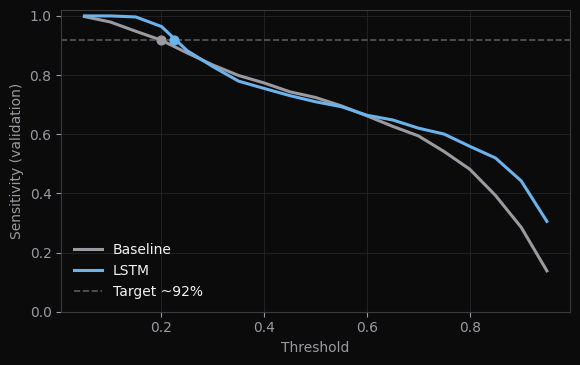

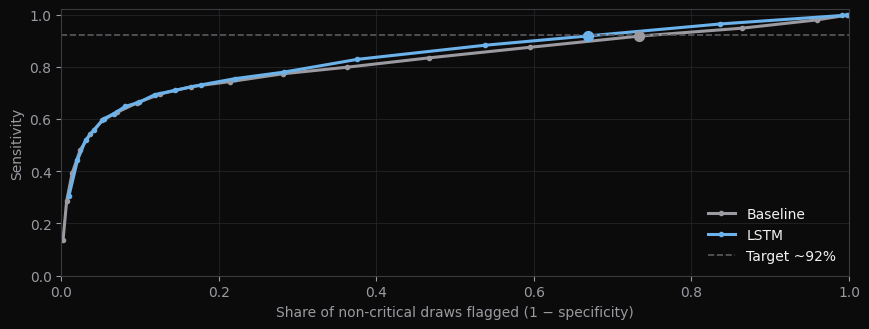

In [18]:
import matplotlib.pyplot as plt

# Dark styling to match the slide deck.
BG, FG, BASE_COLOR, LSTM_COLOR, TARGET_COLOR = "#0B0B0C", "#F2F2F2", "#9A9AA0", "#6CB2EB", "#5A5A60"


def style_axes(ax: plt.Axes) -> None:
    """Apply the dark theme to one Axes (background, spines, ticks, grid, text)."""
    ax.set_facecolor(BG)
    for spine in ax.spines.values():
        spine.set_color("#3A3A3F")
    ax.tick_params(colors=BASE_COLOR)
    ax.xaxis.label.set_color(BASE_COLOR)
    ax.yaxis.label.set_color(BASE_COLOR)
    ax.grid(color="#2A2A2E", linewidth=0.5)
    ax.set_axisbelow(True)


# Operating points chosen earlier on validation: baseline at 0.20, LSTM at the matched threshold.
base_op = baseline_threshold_results.loc[baseline_op_idx]
lstm_op = lstm_fine_sweep.loc[closest_idx]

# ---- Figure A: sensitivity vs. threshold (potassium, validation) ----
fig_a, ax_a = plt.subplots(figsize=(5.9, 3.75), facecolor=BG)
ax_a.plot(baseline_threshold_results["threshold"], baseline_threshold_results["sensitivity"],
          color=BASE_COLOR, linewidth=2.2, label="Baseline")
ax_a.plot(lstm_threshold_results["threshold"], lstm_threshold_results["sensitivity"],
          color=LSTM_COLOR, linewidth=2.2, label="LSTM")
ax_a.axhline(0.92, color=TARGET_COLOR, linestyle="--", linewidth=1.2, label="Target ~92%")
ax_a.scatter([base_op["threshold"]], [base_op["sensitivity"]], color=BASE_COLOR, zorder=5, s=40)
ax_a.scatter([lstm_op["threshold"]], [lstm_op["sensitivity"]], color=LSTM_COLOR, zorder=5, s=40)
ax_a.set_xlabel("Threshold")
ax_a.set_ylabel("Sensitivity (validation)")
ax_a.set_ylim(0, 1.02)
style_axes(ax_a)
leg = ax_a.legend(frameon=False, loc="lower left")
for text in leg.get_texts():
    text.set_color(FG)
fig_a.tight_layout()
fig_a.savefig("fig_sensitivity_vs_threshold.png", dpi=200, facecolor=BG)
plt.show()

# ---- Figure B: sensitivity vs. share of non-critical draws flagged (potassium, validation) ----
fig_b, ax_b = plt.subplots(figsize=(8.8, 3.4), facecolor=BG)
ax_b.plot(1 - baseline_threshold_results["specificity"], baseline_threshold_results["sensitivity"],
          color=BASE_COLOR, linewidth=2.2, marker="o", markersize=3, label="Baseline")
ax_b.plot(1 - lstm_threshold_results["specificity"], lstm_threshold_results["sensitivity"],
          color=LSTM_COLOR, linewidth=2.2, marker="o", markersize=3, label="LSTM")
ax_b.axhline(0.92, color=TARGET_COLOR, linestyle="--", linewidth=1.2, label="Target ~92%")
ax_b.scatter([1 - base_op["specificity"]], [base_op["sensitivity"]], color=BASE_COLOR, zorder=5, s=50)
ax_b.scatter([1 - lstm_op["specificity"]], [lstm_op["sensitivity"]], color=LSTM_COLOR, zorder=5, s=50)
ax_b.set_xlabel("Share of non-critical draws flagged (1 \u2212 specificity)")
ax_b.set_ylabel("Sensitivity")
ax_b.set_xlim(0, 1.0)
ax_b.set_ylim(0, 1.02)
style_axes(ax_b)
leg = ax_b.legend(frameon=False, loc="lower right")
for text in leg.get_texts():
    text.set_color(FG)
fig_b.tight_layout()
fig_b.savefig("fig_tradeoff_potassium.png", dpi=200, facecolor=BG)
plt.show()

In [19]:
def alerts_per_1000(metrics):
    """Alerts raised per 1,000 rows scored, derived from sensitivity/specificity.

    True positives = sensitivity * positives; false positives =
    (1 - specificity) * negatives. Exact arithmetic, not a new measurement.
    """
    tp = metrics["sensitivity"] * metrics["n_positive"]
    fp = (1 - metrics["specificity"]) * (metrics["n_rows"] - metrics["n_positive"])
    return round(1000 * (tp + fp) / metrics["n_rows"], 1)


rows = []
for analyte, name, metrics in [
    ("Potassium", "Baseline (LSTM rows)", baseline_matched_metrics),
    ("Potassium", "LSTM", lstm_test_metrics),
    ("Glucose", "Baseline (LSTM rows)", g_baseline_matched),
    ("Glucose", "LSTM", g_lstm_test),
]:
    row = {"analyte": analyte, **summarize(name, metrics)}
    row["alerts_per_1000_rows"] = alerts_per_1000(metrics)
    rows.append(row)

combined_results = pd.DataFrame(rows).round(4)
combined_results

,analyte,model,threshold,AUPRC,AUROC,sensitivity,specificity,rows_scored,critical_rows,alerts_per_1000_rows
0,Potassium,Baseline (LSTM rows),0.200,0.0991,0.8239,0.9195,0.2665,252538,1478,734.6
1,Potassium,LSTM,0.225,0.1227,0.8426,0.9310,0.3304,252538,1478,671.2
2,Glucose,Baseline (LSTM rows),0.240,0.0785,0.7977,0.9146,0.2568,229832,773,743.8
3,Glucose,LSTM,0.190,0.0569,0.8170,0.9353,0.2937,229832,773,707.1


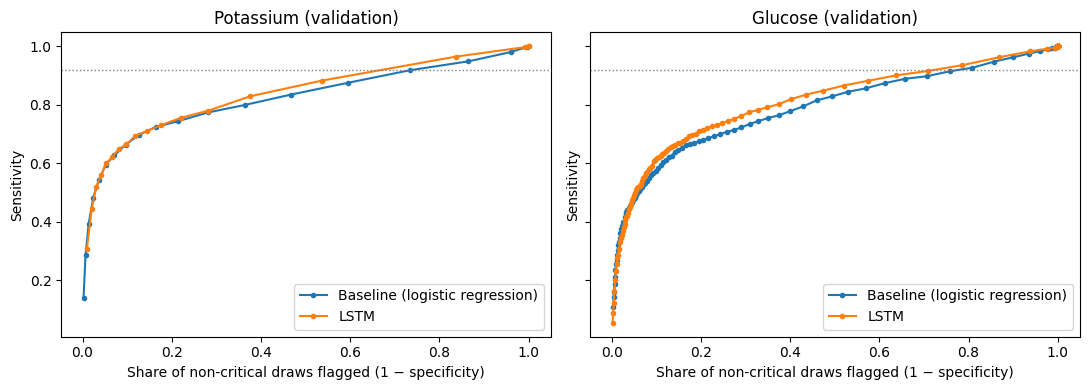

In [20]:
import matplotlib.pyplot as plt


def plot_tradeoff(ax, baseline_sweep, lstm_sweep, title):
    """Sensitivity vs. share of non-critical draws flagged (1 - specificity)."""
    ax.plot(1 - baseline_sweep["specificity"], baseline_sweep["sensitivity"],
            marker="o", markersize=3, label="Baseline (logistic regression)")
    ax.plot(1 - lstm_sweep["specificity"], lstm_sweep["sensitivity"],
            marker="o", markersize=3, label="LSTM")
    ax.axhline(0.92, linestyle=":", color="gray", linewidth=1)
    ax.set_xlabel("Share of non-critical draws flagged (1 − specificity)")
    ax.set_ylabel("Sensitivity")
    ax.set_title(title)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_tradeoff(axes[0], baseline_threshold_results, lstm_threshold_results,
              "Potassium (validation)")
plot_tradeoff(axes[1], g_baseline_sweep, g_lstm_sweep, "Glucose (validation)")
plt.tight_layout()
plt.show()

## Limitations

- **Truncation changes the evaluation population.** Capping sequences at
  the 95th percentile drops early draws from the longest (likely sickest,
  most monitored) admissions for the LSTM. The matched-row table fixes the
  scoring mismatch but not the fact that long-stay patients are only
  partly represented.
- **"Next draw" is not "next hour."** The label is whether the next
  *recorded* draw is critical, however far away it is. A time-window
  label (critical within N hours) is more clinically useful but needs
  resampling to a regular time grid.
- **Draw timing is itself informative.** Clinicians order repeat draws
  when they are worried, so `hours_since_last_draw` partly encodes clinical
  suspicion rather than pure physiology.
- **Some critical values may not be true hyperkalemia.** Hemolyzed
  specimens can produce spuriously high potassium, and no specimen-quality
  signal is used here.
- **Unscaled LSTM inputs.** The baseline standardizes its features, but the
  LSTM was trained on raw values. Standardizing the sequence inputs might
  change the LSTM's results, so the reported gap could be an under- or
  over-estimate.
- **Minimal feature set.** Only three lab-derived features are used. Renal
  function, medications, and diagnoses likely carry real signal.
- **Not deployable.** Precision at ~92% sensitivity is below 1% for both
  models. The finding is a relative reduction in false alarms.
- **Single institution, single split, single run.** MIMIC-IV comes from one
  hospital system. No confidence intervals are reported, and bootstrapping
  the test set would quantify the uncertainty.

## Summary

- A logistic regression on three lab-derived features gives a strong
  baseline for predicting whether the next potassium draw is critical.
- An LSTM over each admission's draw history improved on it, mainly by
  reducing false alarms at the same sensitivity. The improvement is modest,
  and neither model is deployable as an alert system.
- For glucose, the LSTM did not beat the baseline: AUPRC was lower and AUROC roughly equal.
- Several design decisions mattered as much as model choice:
  admission-scoped sequences, plausibility filtering, patient-level
  splits, and comparing models at matched sensitivity rather than at the
  same threshold value.

**To reproduce:** PhysioNet-credentialed MIMIC-IV access on BigQuery, a GCP
billing project, and the four modules (`lab_sequence_pipeline.py`,
`baseline_model.py`, `sequence_dataset.py`, `lstm_model.py`). Random seeds
are fixed for the LSTM; small differences between runs can still occur.


## Appendix

In [21]:
import inspect
import lab_sequence_pipeline, baseline_model, sequence_dataset, lstm_model

for module in (lab_sequence_pipeline, baseline_model, sequence_dataset, lstm_model):
    print("=" * 80)
    print(f"{module.__name__}.py")
    print("=" * 80)
    print(inspect.getsource(module))

lab_sequence_pipeline.py
import logging
import os
from dataclasses import dataclass
from typing import Optional

import pandas as pd
from google.cloud import bigquery
from sklearn.model_selection import train_test_split

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger(__name__)


@dataclass(frozen=True)
class AnalyteConfig:
    """Configuration for a single lab analyte's panic-value pipeline.

    Attributes:
        name: Human-readable analyte name, used in logging and output paths.
        itemid: MIMIC-IV d_labitems itemid for the dominant chemistry draw.
        valid_min: Lower bound for plausibility filtering (drops data errors).
        valid_max: Upper bound for plausibility filtering (drops data errors).
        critical_threshold: Value above which the NEXT draw is labeled critical.
            (For a one-directional panic value, e.g. hyperkalemia.)
    """

    name: str
    itemid: int
    valid_min: floa